Training data shape: (27455, 784)
Testing data shape: (7172, 784)
Number of output classes: 25


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 25)                  │           1,625 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 110,361 (431.10 KB)

 Trainable params: 110,361 (431.10 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.3137 - loss: 2.2493 - val_accuracy: 0.5317 - val_loss: 1.5020
Epoch 2/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.5899 - loss: 1.2867 - val_accuracy: 0.6544 - val_loss: 1.0456
Epoch 3/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7106 - loss: 0.8895 - val_accuracy: 0.7312 - val_loss: 0.7832
Epoch 4/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7889 - loss: 0.6530 - val_accuracy: 0.8176 - val_loss: 0.5809
Epoch 5/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8511 - loss: 0.4731 - val_accuracy: 0.8671 - val_loss: 0.4135
Epoch 6/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8934 - loss: 0.3480 - val_accuracy: 0.8886 - val_loss: 0.3284
Epoch 7/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9225 - loss: 0.2630 - val_accuracy: 0.9013 - val_loss: 0.2899
Epoch 8/11
773/773 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9460 - loss: 0.1926 - val_accuracy: 0.

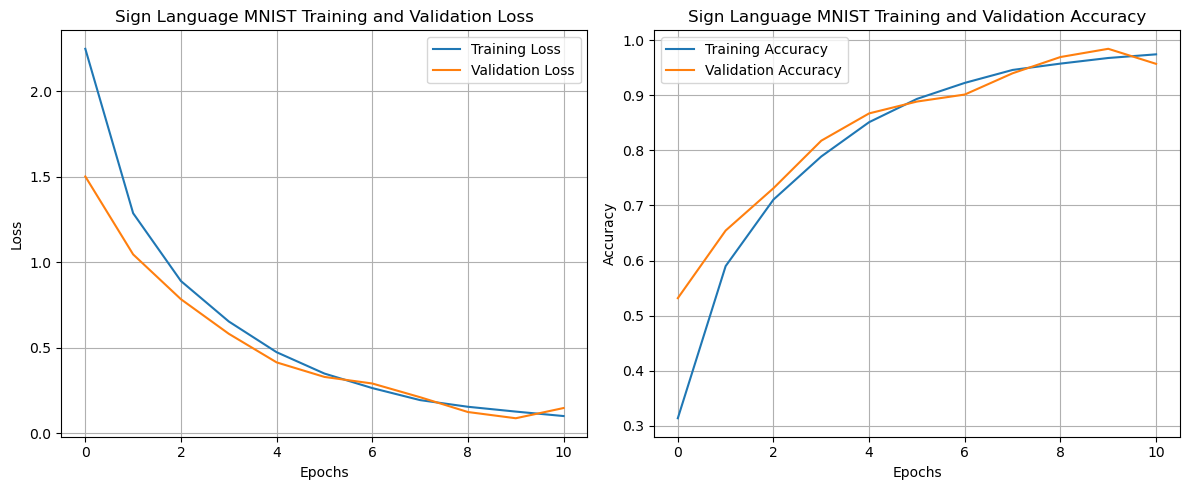

In [2]:

# EXPERIMENT 1E
# Feedforward Neural Network for Sign Language MNIST Classification
# Using Keras and TensorFlow

# a. Import necessary packages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


# b. Load training and testing data

# Read local CSV files
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

# Separate input features and labels
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

# Normalize pixel values between 0 and 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Find the number of output classes
num_classes = int(max(y_train.max(), y_test.max()) + 1)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Number of output classes:", num_classes)


# c. Define the network architecture using Keras

model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
])

# Display model architecture
model.summary()


# Compile the model using Adam optimizer

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# To use SGD instead, replace the optimizer with:
# optimizer=keras.optimizers.SGD(learning_rate=0.01)


# d. Train the model

history = model.fit(
    X_train,
    y_train,
    epochs=11,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)


# e. Evaluate the network

test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")


# f. Plot training loss and accuracy

plt.figure(figsize=(12, 5))

# Plot training and validation loss
plt.subplot(1, 2, 1)

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Sign Language MNIST Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)


# Plot training and validation accuracy
plt.subplot(1, 2, 2)

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Sign Language MNIST Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
